In [41]:
%pip install matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
# Import Pandas for data manipulation
import pandas as pd

# Import Matplotlib for creating charts
import matplotlib.pyplot as plt

# Import Seaborn for statistical visualizations
import seaborn as sns

# Set the chart background style
sns.set_style("whitegrid")

# Load the cleaned dataset
df = pd.read_csv(
    "../data/processed/superstore_clean.csv",
    parse_dates=["Order Date", "Ship Date"]
)

# Restore postal codes to five-digit text format
df["Postal Code"] = (
    df["Postal Code"].astype(str).str.zfill(5)
)

# Display the dataset dimensions
print("Dataset Shape:", df.shape)

# Display the first five records
df.head()

Dataset Shape: (9993, 25)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Year,Order Month,Profit Margin %,Shipping Days
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,2016,11,16.00,3
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,2016,11,30.00,3
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,2016,6,47.00,4
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,2015,10,-40.00,7
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,2015,10,11.25,7


In [43]:
# Calculate total sales
total_sales = df["Sales"].sum()

# Calculate total profit
total_profit = df["Profit"].sum()

# Calculate overall profit margin
profit_margin = (total_profit / total_sales) * 100

# Count unique orders
total_orders = df["Order ID"].nunique()

# Count unique customers
total_customers = df["Customer ID"].nunique()

# Calculate average order value
avg_order_value = total_sales / total_orders

# Display all business KPIs
print("Total Sales:", round(total_sales))
print("Total Profit:", round(total_profit))
print("Profit Margin %:", round(profit_margin, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Average Order Value:", round(avg_order_value, 2))

Total Sales: 2296919
Total Profit: 286409
Profit Margin %: 12.47
Total Orders: 5009
Total Customers: 793
Average Order Value: 458.56


               Sales   Profit
Order Year                   
2014        483966.0  49556.0
2015        470533.0  61619.0
2016        609206.0  81795.0
2017        733215.0  93439.0


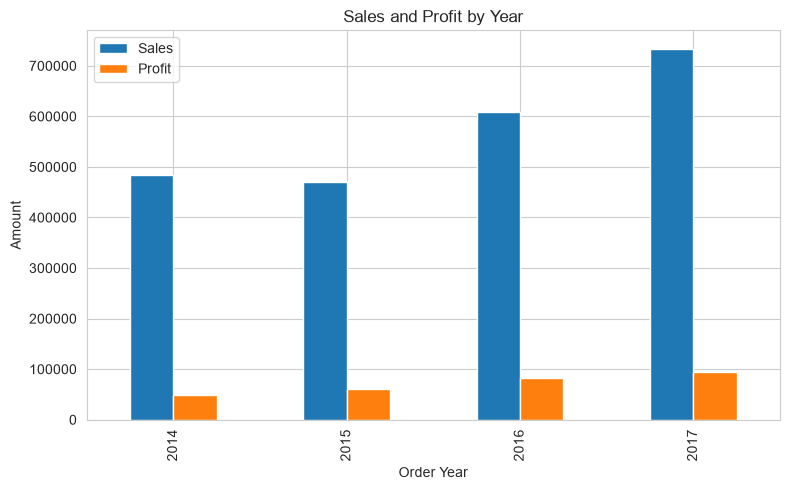

In [44]:
# Group the data by Order Year
# Calculate total Sales and Profit for each year
yearly = df.groupby("Order Year")[["Sales", "Profit"]].sum()

# Display yearly sales and profit
print(yearly.round(0))

# Create a bar chart
yearly.plot(
    kind="bar",
    figsize=(8, 5),
    title="Sales and Profit by Year"
)

# Add Y-axis label
plt.ylabel("Amount")

# Adjust chart layout
plt.tight_layout()

# Save the chart in the visuals folder
plt.savefig("../visuals/yearly_trend.png", dpi=150)

# Display chart
plt.show()

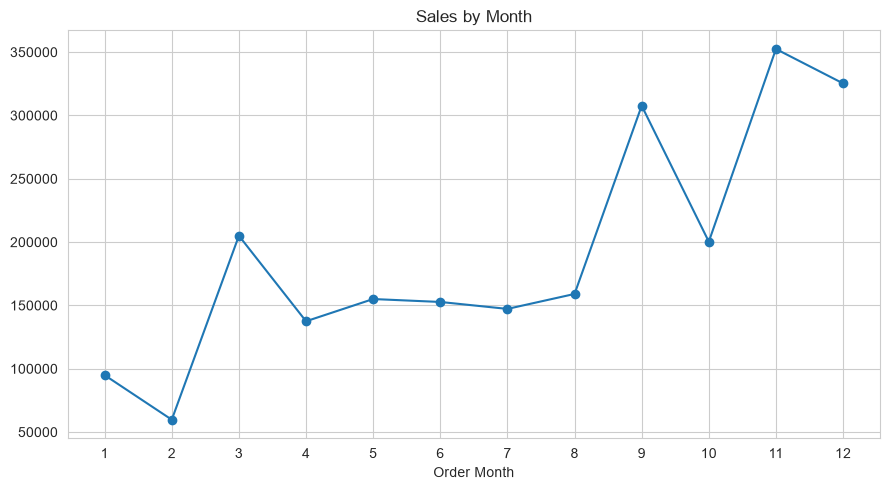

In [45]:
# Group sales by Order Month
monthly = df.groupby("Order Month")["Sales"].sum()

# Create a line chart
monthly.plot(
    kind="line",
    marker="o",
    figsize=(9, 5),
    title="Sales by Month"
)

# Display all 12 months on the X-axis
plt.xticks(range(1, 13))

# Adjust layout
plt.tight_layout()

# Save chart
plt.savefig("../visuals/monthly_sales.png", dpi=150)

# Display chart
plt.show()

Session 1: Observations
1. Overall business performance:
- Total Sales: $2,296,919
- Total Profit: $286,409
- Overall Profit Margin: 12.47%
- The business is profitable overall, generating approximately $286K in profit.
2. Yearly sales and profit trend:
- 2014: Sales $483,966 | Profit $49,556
- 2015: Sales $470,533 | Profit $61,619
- 2016: Sales $609,206 | Profit $81,795
- 2017: Sales $733,215 | Profit $93,439
- Sales decreased slightly in 2015 but increased significantly in 2016 and 2017.
- Profit increased consistently every year.
3. Highest sales month:
- November (Month 11) has the highest sales, approximately $352,000.
- This indicates strong customer demand during November.
4. Lowest sales month:
- February (Month 2) has the lowest sales, approximately $60,000.
- This indicates relatively lower customer demand during February.
5. Business interpretation:
- The business shows positive growth in both sales and profit over the four years.
- November and December show strong sales performance.
- February has comparatively weak sales.
- The company should investigate seasonal demand and plan marketing campaigns or promotional offers during low-sales months.

In [46]:
# Group sales and profit by Category
cat = df.groupby("Category")[["Sales", "Profit"]].sum().round(0)

# Group sales and profit by Sub-Category
# Sort by profit to identify loss-making sub-categories
sub = (
    df.groupby("Sub-Category")[["Sales", "Profit"]]
    .sum()
    .round(0)
    .sort_values("Profit")
)

# Display category results
print("Category Analysis:")
display(cat)

# Display sub-category results
print("Sub-Category Analysis:")
display(sub)

Category Analysis:


,Sales,Profit
Category,,
Furniture,741718.0,18463.0
Office Supplies,719047.0,122491.0
Technology,836154.0,145455.0


Sub-Category Analysis:


,Sales,Profit
Sub-Category,,
Tables,206966.0,-17725.0
Bookcases,114880.0,-3473.0
Supplies,46674.0,-1189.0
Fasteners,3024.0,950.0
Machines,189239.0,3385.0
Labels,12486.0,5546.0
Art,27119.0,6528.0
Envelopes,16476.0,6964.0
Furnishings,91705.0,13059.0


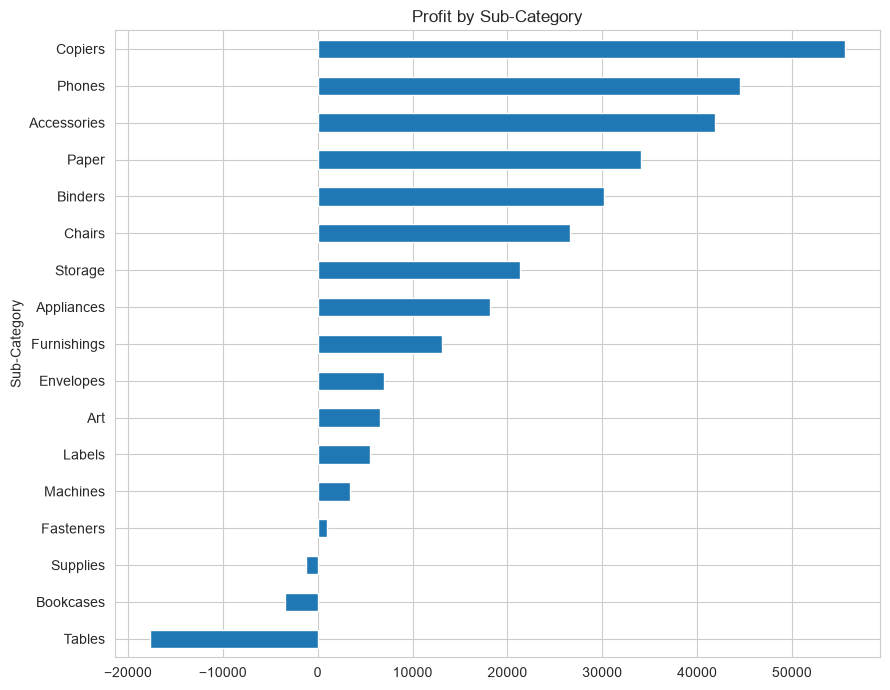

In [47]:
# Plot profit by sub-category
sub["Profit"].plot(
    kind="barh",
    figsize=(9, 7),
    title="Profit by Sub-Category"
)

# Adjust chart layout
plt.tight_layout()

# Save chart
plt.savefig(
    "../visuals/profit_by_subcategory.png",
    dpi=150
)

# Display chart
plt.show()

In [48]:
# Group sales and profit by Region
region = (
    df.groupby("Region")[["Sales", "Profit"]]
    .sum()
    .round(0)
    .sort_values("Profit")
)

# Display regional performance
print("Regional Analysis:")
display(region)

Regional Analysis:


,Sales,Profit
Region,,
Central,501240.0,39706.0
South,391722.0,46749.0
East,678500.0,91535.0
West,725458.0,108418.0


In [49]:
# Compare profit across regions and categories
region_category = (
    df.groupby(["Region", "Category"])["Profit"]
    .sum()
    .round(0)
    .unstack()
)

# Display comparison table
print("Region vs Category Profit:")
display(region_category)

Region vs Category Profit:


Category,Furniture,Office Supplies,Technology
Region,,,
Central,-2871.0,8880.0,33697.0
East,3058.0,41015.0,47462.0
South,6771.0,19986.0,19992.0
West,11505.0,52610.0,44304.0


In [50]:
# Group profit by State
# Sort in ascending order to get the lowest-profit states
worst_states = (
    df.groupby("State")["Profit"]
    .sum()
    .round(0)
    .sort_values()
    .head(10)
)

# Display the 10 worst-performing states
print("10 Lowest Profit States:")
display(worst_states)

10 Lowest Profit States:


State
Texas            -25729.0
Ohio             -16959.0
Pennsylvania     -15560.0
Illinois         -12608.0
North Carolina    -7491.0
Colorado          -6528.0
Tennessee         -5342.0
Arizona           -3428.0
Florida           -3399.0
Oregon            -1190.0
Name: Profit, dtype: float64

In [51]:
# Group sales and profit by customer segment
segment = (
    df.groupby("Segment")[["Sales", "Profit"]]
    .sum()
    .round(0)
)

# Display segment performance
print("Customer Segment Analysis:")
display(segment)

Customer Segment Analysis:


,Sales,Profit
Segment,,
Consumer,1161401.0,134119.0
Corporate,706146.0,91979.0
Home Office,429372.0,60311.0


Session 2: Observations
1. Best-performing category:
- Technology is the most profitable category, generating approximately $145,455 in profit.
- Office Supplies contributes around $122,491, while Furniture contributes around $18,463.
2. Most profitable sub-category:
- Copiers generate the highest profit of approximately $55,618.
- Phones ($44,516) and Accessories ($41,937) are the next strongest sub-categories.
3. Loss-making sub-categories:
- Tables have the highest loss of approximately $17,725.
- Bookcases lose around $3,473.
- Supplies lose around $1,189.
- These three sub-categories need pricing and discount strategy improvements.
4. Weakest region:
- Central is the weakest region, generating approximately $39,706 in profit.
- West performs best, with approximately $104,818 in profit.
- Central's Furniture category is loss-making (-$2,871).
5. Worst-performing states:
- Texas has the highest loss of approximately $25,729.
- Ohio ($16,959) and Pennsylvania ($15,560) are the next biggest loss-making states.
- These states need further investigation into discounts, pricing and product performance.
6. Best-performing customer segment:
- Consumer is the strongest segment, generating $1,161,401 in sales and $134,119 in profit.
- Corporate generates $91,979 profit.
- Home Office generates $60,311 profit.
- Consumer customers contribute the largest share of business revenue and profit.
7. Business recommendations:
- Focus on promoting high-profit products such as Copiers, Phones and Accessories.
- Review discount and pricing strategies for Tables, Bookcases and Supplies.
- Investigate losses in Texas, Ohio and Pennsylvania.
- Develop strategies to improve profitability in the Central region.
- Focus on retaining Consumer customers while growing Corporate and Home Office segments.

In [52]:
# Create discount groups using specified ranges
df["Discount Band"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.1, 0.2, 0.3, 0.5, 1],
    labels=[
        "0%",
        "0-10%",
        "10-20%",
        "20-30%",
        "30-50%",
        "50%+"
    ]
)

# Group records by Discount Band
# Calculate number of records, total sales and total profit
disc = df.groupby(
    "Discount Band",
    observed=True
).agg(
    Orders=("Profit", "size"),
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

# Calculate profit margin for each discount group
disc["Margin %"] = (
    disc["Profit"] / disc["Sales"] * 100
).round(1)

# Display discount analysis
display(disc.round(0))

,Orders,Sales,Profit,Margin %
Discount Band,,,,
0%,4798,1087908.0,320988.0,30.0
0-10%,94,54369.0,9029.0,17.0
10-20%,3709,792153.0,91756.0,12.0
20-30%,226,102945.0,-10357.0,-10.0
30-50%,310,195315.0,-48448.0,-25.0
50%+,856,64229.0,-76559.0,-119.0


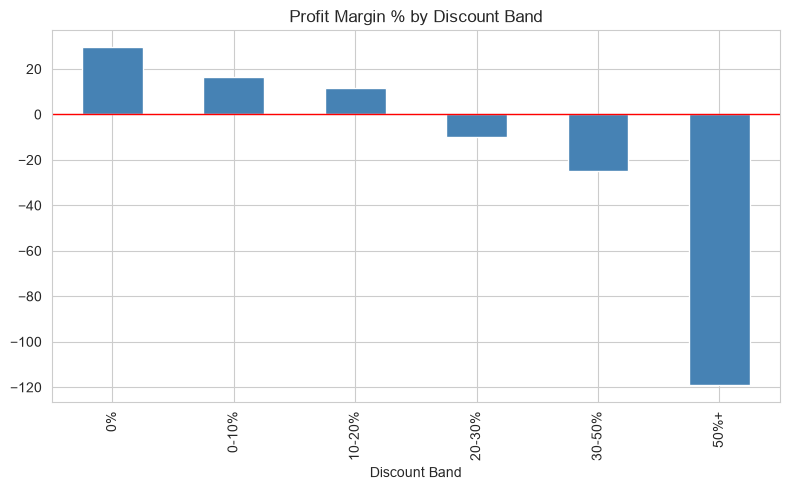

In [53]:
# Plot profit margin for each discount band
disc["Margin %"].plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue",
    title="Profit Margin % by Discount Band"
)

# Add a horizontal zero-profit reference line
plt.axhline(0, color="red", linewidth=1)

# Adjust chart layout
plt.tight_layout()

# Save chart
plt.savefig(
    "../visuals/discount_vs_margin.png",
    dpi=150
)

# Display chart
plt.show()

In [54]:
# Filter records where profit is negative
losses = df[df["Profit"] < 0]

# Calculate percentage of loss-making records
loss_percentage = len(losses) / len(df) * 100

# Calculate total profit from loss-making records
total_losses = losses["Profit"].sum()

# Display results
print(
    "Loss-making rows %:",
    round(loss_percentage, 1)
)

print(
    "Total losses:",
    round(total_losses)
)

Loss-making rows %: 18.7
Total losses: -156119


In [55]:
# Group sales and profit by customer name
cust = (
    df.groupby("Customer Name")[["Sales", "Profit"]]
    .sum()
    .round(0)
)

# Display the 10 most profitable customers
print("Top 10 Profitable Customers:")
display(
    cust.sort_values(
        "Profit",
        ascending=False
    ).head(10)
)

# Display the 5 customers with the lowest profit
print("5 Lowest Profit Customers:")
display(
    cust.sort_values("Profit").head(5)
)

Top 10 Profitable Customers:


,Sales,Profit
Customer Name,,
Tamara Chand,19052.0,8981.0
Raymond Buch,15117.0,6976.0
Sanjit Chand,14142.0,5757.0
Hunter Lopez,12873.0,5622.0
Adrian Barton,14474.0,5445.0
Tom Ashbrook,14596.0,4704.0
Christopher Martinez,8954.0,3900.0
Keith Dawkins,8181.0,3039.0
Andy Reiter,6608.0,2885.0


5 Lowest Profit Customers:


,Sales,Profit
Customer Name,,
Cindy Stewart,5690.0,-6626.0
Grant Thornton,9351.0,-4109.0
Luke Foster,3931.0,-3584.0
Sharelle Roach,3233.0,-3334.0
Henry Goldwyn,3248.0,-2798.0


In [56]:
# Group sales and profit by product name
prod = (
    df.groupby("Product Name")[["Sales", "Profit"]]
    .sum()
    .round(0)
    .sort_values("Profit")
)

# Display the 5 biggest loss-making products
print("Top 5 Loss-Making Products:")
display(prod.head(5))

# Display the 5 most profitable products
print("Top 5 Profitable Products:")
display(prod.tail(5))

Top 5 Loss-Making Products:


,Sales,Profit
Product Name,,
Cubify CubeX 3D Printer Double Head Print,11100.0,-8880.0
Lexmark MX611dhe Monochrome Laser Printer,16830.0,-4590.0
Cubify CubeX 3D Printer Triple Head Print,8000.0,-3840.0
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,9918.0,-2876.0
Bush Advantage Collection Racetrack Conference Table,9545.0,-1934.0


Top 5 Profitable Products:


,Sales,Profit
Product Name,,
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18375.0,4095.0
Canon PC1060 Personal Laser Copier,11620.0,4571.0
Hewlett Packard LaserJet 3310 Copier,18840.0,6984.0
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.0,7753.0
Canon imageCLASS 2200 Advanced Copier,61600.0,25200.0


Session 3: Observations
1. Discount band with the highest profit margin:
The 0% discount band has the highest profit margin of 30%, generating a profit of $320,988. This indicates that selling without discounts is more profitable.

2. Discount band with the lowest profit margin:
The 50%+ discount band has the lowest margin of -119%, resulting in a loss of $76,559. Higher discounts are significantly reducing profitability.

3. Percentage of loss-making records:
Approximately 18.7% of records generate negative profit, resulting in total losses of approximately $156,119.

4. Most profitable customer:
Tamara Chand is the most profitable customer, generating $8,981 in profit from $19,052 in sales.

5. Lowest-profit customers:
Cindy Stewart is the biggest loss-making customer, with a loss of $6,626. Other customers contributing to losses include Grant Thornton, Luke Foster, Sharelle Roach, and Henry Goldwyn.

6. Biggest loss-making products:
- Cubify CubeX 3D Printer Double Head Print: -$8,880
- Lexmark MX611dhe Monochrome Laser Printer: -$4,590
- Cubify CubeX 3D Printer Triple Head Print: -$3,840
- Chromcraft Bull-Nose Conference Tables: -$2,876
- Bush Advantage Collection Conference Table: -$1,934
7. Most profitable products:
- Canon imageCLASS 2200 Advanced Copier: $25,200
- Fellowes PB500 Electric Punch: $7,753
- Hewlett Packard LaserJet 3310 Copier: $6,984
- Canon PC1060 Personal Laser Copier: $4,571
- HP Designjet T520 Inkjet Printer: $4,095
8. Business recommendations:
- Reduce excessive discounts, especially those above 20%, as they are generating negative profit margins.
- Review pricing and costs of loss-making products, particularly Tables and 3D printers.
- Focus on promoting highly profitable products such as Canon copiers.
- Identify customer purchasing patterns to reduce losses from unprofitable customers.
- Continue investing in profitable categories and monitor sales and profit growth.

In [57]:
# Calculate percentage change in yearly sales
yearly["Sales Growth %"] = (
    yearly["Sales"].pct_change() * 100
).round(2)

# Display yearly sales growth
display(yearly)

,Sales,Profit,Sales Growth %
Order Year,,,
2014,483966.1261,49556.0329,NaN
2015,470532.5090,61618.6037,-2.78
2016,609205.5980,81795.1743,29.47
2017,733215.2552,93439.2696,20.36


Interpretation: Sales declined slightly in 2015 but recovered strongly in 2016 and 2017. The business showed positive growth in the last two years.

## Key Findings

### Finding 1: Overall Business Performance

- **Finding:** The business generated approximately **$2.30 million in sales** and **$286,409 in profit**, with a profit margin of **12.47%**. Sales increased by 20.36% in 2017 compared to 2016.
- **Why it matters:** The business shows positive growth and increasing profitability, although there is still room to improve profit margins.
- **Recommendation:** Focus on maintaining sales growth while improving pricing strategies and controlling unnecessary costs.

### Finding 2: Category Performance

- **Finding:** Technology is the most profitable category, generating approximately **$145,435 in profit**. Copiers are the most profitable sub-category with $55,618 profit. Tables, Bookcases, and Supplies generate negative profits.
- **Why it matters:** Not all products contribute equally to business profitability. Some products generate high sales but still result in losses.
- **Recommendation:** Invest more in profitable categories and review the pricing, discounting, and costs of loss-making sub-categories.

### Finding 3: Regional Performance

- **Finding:** The West region is the strongest performer, generating $104,818 in profit, while the Central region is the weakest with $39,706. Texas has the highest state-level loss of approximately $25,729.
- **Why it matters:** Regional performance differences indicate opportunities to improve sales and profitability in weaker markets.
- **Recommendation:** Investigate the reasons behind losses in the Central region and Texas, and apply successful strategies from the West region.

### Finding 4: Discount Analysis

- **Finding:** Products sold without discounts generate the highest profit margin of 30%. Discounts above 20% result in negative profit margins, with the 50%+ discount band reaching -119%.
- **Why it matters:** Excessive discounting significantly reduces profitability and can turn sales into losses.
- **Recommendation:** Reduce excessive discounts, introduce controlled discount limits, and evaluate profitability before offering promotions.

### Finding 5: Customer Analysis

- **Finding:** Tamara Chand is the most profitable customer, generating $8,981 in profit. Cindy Stewart is the biggest loss-making customer, with a loss of $6,626. The Consumer segment generates the highest profit of $134,119.
- **Why it matters:** Understanding customer profitability helps businesses identify valuable customers and reduce losses from unprofitable transactions.
- **Recommendation:** Focus on retaining high-value customers, understand purchasing patterns, and review pricing and discount strategies for loss-making customers.

### Finding 6: Product Performance

- **Finding:** Canon imageCLASS 2200 Advanced Copier is the most profitable product, generating $25,200 in profit. Cubify CubeX 3D Printer Double Head Print is the biggest loss-making product, with a loss of $8,880.
- **Why it matters:** Product-level profitability helps identify which products contribute most to business growth and which products need attention.
- **Recommendation:** Promote high-profit products, review the costs and pricing of loss-making products, and consider reducing or discontinuing consistently unprofitable products.